In [1]:
# --- bootstrap: dodaj katalog projektu do sys.path (dziala z notebooks/ i z root) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while not (_p / 'config.py').exists() and _p != _p.parent:
    _p = _p.parent
if str(_p) not in sys.path:
    sys.path.insert(0, str(_p))
from IPython.display import display

import config


# Notebook 01a: klasyfikator wydawcy (HerBERT)

Etap stroi i uczy klasyfikator rozpoznający wydawcę na podstawie samego nagłówka, a następnie zapisuje predykcje dla wszystkich podzbiorów.

Wejście: podzbiory z notebooka `00`.
Wyjście: `models/herbert_best_model/` oraz `data/dane_z_prawdopodobienstwem.csv` - plik wejściowy dla notebooków `01b`, `02`, `03` i `04`.

Logika siedzi w `src/classifier.py`, notebook ją wywołuje i pokazuje wyniki. Strojenie i trening wymagają GPU i trwają godzinami, dlatego obie komórki domyślnie nie liczą niczego od nowa: Optuna wczytuje istniejące próby z bazy, a trening wczytuje zapisany model z dysku.

## 1. Dane i tokenizacja

Jedno wywołanie wczytuje podzbiory, tokenizuje nagłówki i liczy wagi klas. Wagi powstają wyłącznie na zbiorze treningowym - policzenie ich na całości przeniosłoby do uczenia informację o rozkładzie klas w teście.

In [2]:
from src import classifier
from src import data as ds

ramki = ds.load_splits()
for nazwa, d in ramki.items():
    print(f"  {nazwa:<6} {len(d):>6} rekordów")

przygotowane = classifier.prepare_datasets(ramki)
tokenizer = przygotowane["tokenizer"]
tokenized = przygotowane["tokenized"]
class_weights = przygotowane["class_weights"]
print(f"Wagi klas (balanced): {class_weights.numpy().round(3)}")

  train   27264 rekordów
  valid   15843 rekordów
  test    12807 rekordów


d:\ARTYKUL\venv312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Map: 100%|██████████| 12807/12807 [00:00<00:00, 22785.89 examples/s]


Wagi klas (balanced): [0.919 1.003 1.093]


## 2. Punkty odniesienia

Klasyfikator kontekstowy porównany z regułą większościową i z modelami liniowymi na TF-IDF, uczonymi na tym samym zbiorze treningowym. Różnica mówi, jaka część zadania daje się rozwiązać samymi cechami leksykalnymi, bez modelowania kontekstu.

In [3]:
baseline, slownik = classifier.baselines(
    ramki["train"], ramki["test"], valid_df=ramki["valid"], return_vocab=True)
print(baseline.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print()
print(f"Słownik TF-IDF: {slownik['vocab_filtered']} termów "
      f"(bez filtrowania {slownik['vocab_unfiltered']})")

Embeddingi zamrozonego enkodera wczytane z frozen_herbert_embeddings.npy
                        model  accuracy_valid  f1_macro_valid  accuracy_test  f1_macro_test
          Klasa większościowa           0.356           0.175          0.419          0.197
TF-IDF + regresja logistyczna           0.668           0.662          0.682          0.671
         TF-IDF + liniowy SVM           0.649           0.643          0.659          0.647
    HerBERT (bez dostrojenia)           0.337           0.333          0.335          0.328

Słownik TF-IDF: 23775 termów (bez filtrowania 218524)


## 3. Strojenie hiperparametrów

Przestrzeń przeszukiwania, funkcja celu i reguła przycinania prób siedzą w `src/classifier.py`. Kryterium jest F1-macro na zbiorze walidacyjnym, nie trafność - klasy są nierówne, więc trafność nagradzałaby przewidywanie klasy najliczniejszej.

`N_TRIALS = 0` wczytuje istniejące próby z bazy Optuny bez liczenia czegokolwiek. Podniesienie tej wartości uruchamia strojenie, które wymaga GPU i trwa godzinami.

In [5]:
import optuna
import pandas as pd
import torch

N_TRIALS = 0
METRYKA = "eval_f1_macro"

print(f"Optuna {optuna.__version__} | prób do uruchomienia: {N_TRIALS} | metryka: {METRYKA}")
print(f"CUDA: {torch.cuda.is_available()}"
      + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))
print(f"Przestrzeń przeszukiwania: {len(classifier.SEARCH_SPACE)} hiperparametrów")

study = classifier.tune_hyperparameters(
    tokenized["train"], tokenized["valid"], class_weights,
    n_trials=N_TRIALS, metric=METRYKA,
)

stany = {}
for proba in study.trials:
    stany[proba.state.name] = stany.get(proba.state.name, 0) + 1
print(f"Najlepsza próba: #{study.best_trial.number}, {METRYKA} = {study.best_value:.4f}")
print(f"Stany prób: {stany}")

proby = pd.read_csv(config.DATA / "herbert_optuna_all_trials.csv")
proby.sort_values("value", ascending=False).head(5)

[I 2026-10-10 17:43:55,344] Using an existing study with name 'herbert_finetune' instead of creating a new one.


Optuna 4.9.0 | prób do uruchomienia: 0 | metryka: eval_f1_macro
CUDA: True (NVIDIA GeForce RTX 4060 Ti)
Przestrzeń przeszukiwania: 13 hiperparametrów
Najlepsza próba: #381, eval_f1_macro = 0.7747
Stany prób: {'COMPLETE': 35, 'PRUNED': 477, 'FAIL': 7, 'RUNNING': 1}


,number,value,datetime_start,datetime_complete,duration,params_adam_beta2,params_attention_probs_dropout_prob,params_decay_rate,params_focal_loss_gamma,params_hidden_dropout_prob,params_label_smoothing_factor,params_learning_rate,params_lr_scheduler_type,params_num_frozen_layers,params_num_train_epochs,params_per_device_train_batch_size,params_warmup_ratio,params_weight_decay,state
381,381,0.774656,2026-10-10 10:24:04.765838,2026-10-10 10:41:40.916690,0 days 00:17:36.150852,0.999,0.120521,0.940518,2.891409,0.102452,0.139681,0.000029,cosine,0,4,32,0.028809,0.028362,COMPLETE
274,274,0.772709,2026-10-09 20:27:53.379440,2026-10-09 20:43:49.429813,0 days 00:15:56.050373,0.999,0.100147,0.922198,2.791886,0.105009,0.148876,0.000028,cosine,1,4,32,0.007966,0.018311,COMPLETE
404,404,0.770230,2026-10-10 11:48:29.076168,2026-10-10 12:04:33.619973,0 days 00:16:04.543805,0.999,0.100555,0.906054,2.774571,0.106150,0.149678,0.000029,cosine,1,4,32,0.024449,0.030230,COMPLETE
502,502,0.769051,2026-10-10 15:31:20.105253,2026-10-10 15:49:46.207233,0 days 00:18:26.101980,0.999,0.127750,0.910516,2.619200,0.108759,0.124134,0.000030,cosine,0,4,16,0.011626,0.350223,COMPLETE
202,202,0.768857,2026-10-09 17:40:03.311873,2026-10-09 17:57:28.147666,0 days 00:17:24.835793,0.999,0.129637,0.906330,1.254073,0.118104,0.138969,0.000029,cosine,0,4,32,0.009200,0.058448,COMPLETE


## 4. Model finalny

Trening na najlepszej konfiguracji, wyłącznie na zbiorze treningowym; walidacyjny służy do wyboru epoki przez wczesne zatrzymanie. Wielkość wsadu jest utrzymywana akumulacją gradientu, więc efektywny wsad nie zależy od tego, ile mieści się w pamięci karty.

`force_retrain=False` wczytuje zapisany model z dysku zamiast uczyć od nowa.

In [7]:
best_params = classifier.load_best_params()
for klucz, wartosc in sorted(best_params.items()):
    print(f"  {klucz} = {wartosc}")

wsad = best_params.get("per_device_train_batch_size", 32)
print(f"Wsad na urządzenie {wsad}, akumulacja gradientu "
      f"{max(1, classifier.TARGET_BATCH_SIZE // wsad)} krok(i), "
      f"efektywny wsad {classifier.TARGET_BATCH_SIZE}")

trainer = classifier.train_final_model(
    best_params, tokenized["train"], tokenized["valid"], tokenizer, class_weights,
    force_retrain=False,
)

  adam_beta2 = 0.999
  attention_probs_dropout_prob = 0.1205208926386869
  decay_rate = 0.940517883655435
  focal_loss_gamma = 2.891408878477484
  hidden_dropout_prob = 0.10245159762585518
  label_smoothing_factor = 0.1396809616906594
  learning_rate = 2.9475896840116445e-05
  lr_scheduler_type = cosine
  num_frozen_layers = 0
  num_train_epochs = 4
  per_device_train_batch_size = 32
  warmup_ratio = 0.02880895755977295
  weight_decay = 0.028362374324022332
Wsad na urządzenie 32, akumulacja gradientu 1 krok(i), efektywny wsad 32


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at allegro/herbert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  3%|▎         | 101/3408 [00:15<08:02,  6.85it/s]

{'loss': 0.312, 'grad_norm': inf, 'learning_rate': 1.3281244782596865e-05, 'epoch': 0.12}


  6%|▌         | 201/3408 [00:30<07:41,  6.95it/s]

{'loss': 0.2298, 'grad_norm': 3.54085373878479, 'learning_rate': 1.325133875309941e-05, 'epoch': 0.23}


...

{'loss': 0.0782, 'grad_norm': 4.393754482269287, 'learning_rate': 2.992827864465259e-10, 'epoch': 3.99}


                                                   
100%|██████████| 3408/3408 [09:39<00:00,  6.78it/s]

{'eval_loss': 0.23249059915542603, 'eval_accuracy': 0.7655115824023228, 'eval_f1_macro': 0.7609085394905023, 'eval_precision_macro': 0.761801065030979, 'eval_recall_macro': 0.7682314350216403, 'eval_f1_Niezależna': 0.8028060569766448, 'eval_precision_Niezależna': 0.7752808988764045, 'eval_recall_Niezależna': 0.8323576370409792, 'eval_f1_OKO.press': 0.768090363572185, 'eval_precision_OKO.press': 0.849170731707317, 'eval_recall_OKO.press': 0.7011438698243918, 'eval_f1_RP': 0.7118291979226774, 'eval_precision_RP': 0.6609515645092156, 'eval_recall_RP': 0.7711927981995499, 'eval_runtime': 16.0, 'eval_samples_per_second': 990.188, 'eval_steps_per_second': 31.0, 'epoch': 4.0}


100%|██████████| 3408/3408 [09:41<00:00,  5.86it/s]


{'train_runtime': 581.6252, 'train_samples_per_second': 187.502, 'train_steps_per_second': 5.859, 'train_loss': 0.1273551984851909, 'epoch': 4.0}


## 5. Predykcje i ewaluacja

Predykcje dla wszystkich trzech podzbiorów trafiają do jednego pliku, dzięki czemu tabele w notebooku `04` i analizy w `02` i `03` opisują ten sam przebieg.

100%|██████████| 401/401 [00:12<00:00, 31.27it/s]


Zapisano dane_z_prawdopodobienstwem.csv: 55914 rekordów


,Gazeta,Zbiór,Accuracy,Precision,Recall,F1-Score,Liczba
0,Niezależna,treningowy,0.9306,0.9392,0.9511,0.9451,9891
1,OKO.press,treningowy,,0.9585,0.9084,0.9328,9057
2,RP,treningowy,,0.8930,0.9305,0.9114,8316
3,Średnia ważona,treningowy,0.9306,0.9315,0.9306,0.9307,27264
4,Niezależna,walidacyjny,0.7688,0.7848,0.8203,0.8022,5637
5,OKO.press,walidacyjny,,0.8324,0.7234,0.7741,6207
6,RP,walidacyjny,,0.6728,0.7667,0.7167,3999
7,Średnia ważona,walidacyjny,0.7688,0.7752,0.7688,0.7696,15843
8,Niezależna,testowy,0.7625,0.8208,0.7987,0.8096,5364
9,OKO.press,testowy,,0.8022,0.7578,0.7794,4517


Błędów na teście: 3042 z 12807 (accuracy 0.7625) - tyle nagłówków trafia do notebooka 03


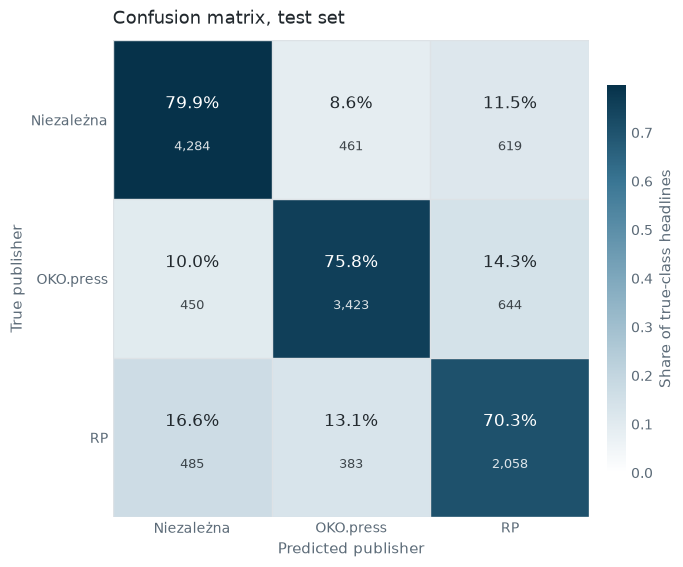

In [8]:
from src.evaluation import metrics_table
from src.visualization import plot_confusion_matrix

dane, surowe = classifier.predict_splits(
    trainer, tokenized, ramki,
)
print(f"Zapisano {config.PROBS_CSV.name}: {len(dane)} rekordów")

tabela = pd.concat(
    [metrics_table(d["label"], d["predicted_label"], nazwa)
     for nazwa, d in (("treningowy", dane[dane["split"] == "train"]),
                      ("walidacyjny", dane[dane["split"] == "valid"]),
                      ("testowy", dane[dane["split"] == "test"]))],
    ignore_index=True)
display(tabela)

test = dane[dane["split"] == "test"]
plot_confusion_matrix(test["label"], test["predicted_label"],
                      title="Confusion matrix, test set",
                      save_path=config.FIGURES / "01_macierz_pomylek_test_udzialy.png")

bledy = int((test["label"] != test["predicted_label"]).sum())
print(f"Błędów na teście: {bledy} z {len(test)} "
      f"(accuracy {1 - bledy / len(test):.4f}) - tyle nagłówków trafia do notebooka 03")

## 6. Ablacja straty i rozrzut po ziarnach

Krok opcjonalny. Odpowiada na dwa pytania: ile wnosi strata ogniskowa ponad samą ważoną entropię krzyżową oraz jak duży jest rozrzut wyniku między ziarnami losowymi. Bez drugiej liczby nie wiadomo, czy przewaga nad punktem odniesienia mieści się w szumie.

Każdy wariant to pełne dostrojenie modelu, więc całość trwa kilkakrotnie dłużej niż sam trening finalny. Dlatego krok uruchamia się jawnie.

In [ ]:
URUCHOM_ABLACJE = False

if URUCHOM_ABLACJE:
    ablacja = classifier.loss_ablation(
        best_params, tokenized["train"], tokenized["valid"], tokenized["test"],
        class_weights, seeds=(42, 1, 2),
    )
    display(ablacja)
else:
    print("Ablacja pominięta. Ustaw URUCHOM_ABLACJE = True, aby ją policzyć.")

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at allegro/herbert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{'loss': 0.2257, 'grad_norm': 3.73732590675354, 'learning_rate': 9.429377336662505e-06, 'epoch': 0.5868544600938967}
{'eval_loss': 0.20015226304531097, 'eval_accuracy': 0.7316796061352017, 'eval_f1_macro': 0.7308683269733668, 'eval_precision_macro': 0.7432572343793629, 'eval_recall_macro': 0.7439515257344972, 'eval_f1_Niezależna': 0.7662517289073306, 'eval_precision_Niezależna': 0.8646599777034559, 'eval_recall_Niezależna': 0.6879545857725741, 'eval_f1_OKO.press': 0.7398103050499872, 'eval_precision_OKO.press': 0.7876637554585153, 'eval_recall_OKO.press': 0.6974383760270663, 'eval_f1_RP': 0.6865429469627827, 'eval_precision_RP': 0.5774479699761174, 'eval_recall_RP': 0.846461615403851, 'eval_runtime': 14.6445, 'eval_samples_per_second': 1081.841, 'eval_steps_per_second': 33.869, 'epoch': 1.0}
{'loss': 0.1665, 'grad_norm': 9.95824909210205, 'learning_rate': 8.02435510453334e-06, 'epoch': 1.1737089201877935}
{'loss': 0.146, 'grad_norm': 7.374649524688721, 'learning_rate': 5.96168039261187

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at allegro/herbert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{'loss': 0.8277, 'grad_norm': 7.983712196350098, 'learning_rate': 9.433212709255773e-06, 'epoch': 0.5868544600938967}
{'eval_loss': 0.7650273442268372, 'eval_accuracy': 0.7463864167140062, 'eval_f1_macro': 0.7433806562094781, 'eval_precision_macro': 0.746911975873472, 'eval_recall_macro': 0.7536337640683612, 'eval_f1_Niezależna': 0.793731778425656, 'eval_precision_Niezależna': 0.8158831241805582, 'eval_recall_Niezależna': 0.7727514635444386, 'eval_f1_OKO.press': 0.7489906968579955, 'eval_precision_OKO.press': 0.8226335068440331, 'eval_recall_OKO.press': 0.6874496536168841, 'eval_f1_RP': 0.6874194933447831, 'eval_precision_RP': 0.6022192965958247, 'eval_recall_RP': 0.8007001750437609, 'eval_runtime': 14.937, 'eval_samples_per_second': 1060.657, 'eval_steps_per_second': 33.206, 'epoch': 1.0}
{'loss': 0.7004, 'grad_norm': 19.318805694580078, 'learning_rate': 8.031542625275421e-06, 'epoch': 1.1737089201877935}
{'loss': 0.6605, 'grad_norm': 9.589448928833008, 'learning_rate': 5.970687461396

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at allegro/herbert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{'loss': 0.2268, 'grad_norm': 2.6434662342071533, 'learning_rate': 9.429377336662505e-06, 'epoch': 0.5868544600938967}
{'eval_loss': 0.20852912962436676, 'eval_accuracy': 0.7190557343937386, 'eval_f1_macro': 0.7175488577536937, 'eval_precision_macro': 0.7280299250326765, 'eval_recall_macro': 0.7300556709132165, 'eval_f1_Niezależna': 0.7752142386288727, 'eval_precision_Niezależna': 0.8261742272179847, 'eval_recall_Niezależna': 0.7301756253326237, 'eval_f1_OKO.press': 0.7189751801441153, 'eval_precision_OKO.press': 0.8027413587604291, 'eval_recall_OKO.press': 0.6510391493475108, 'eval_f1_RP': 0.6584571544880928, 'eval_precision_RP': 0.5551741891196156, 'eval_recall_RP': 0.8089522380595149, 'eval_runtime': 14.5136, 'eval_samples_per_second': 1091.6, 'eval_steps_per_second': 34.175, 'epoch': 1.0}
{'loss': 0.1691, 'grad_norm': 4.2479424476623535, 'learning_rate': 8.027950205830563e-06, 'epoch': 1.1737089201877935}
{'loss': 0.1477, 'grad_norm': 2.546630859375, 'learning_rate': 5.966184372582

KeyboardInterrupt: 